In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.titlesize': 13, 'axes.titleweight': 'bold'})



##  Loading Dataset

In [15]:

df = pd.read_excel('version 1.xlsx')
#here we are renaming the columns for further use
df = df.rename(columns={
    'Actual data of'                              : 'Date',
    'Max. Demand at eve. peak (Generation end)'   : 'Demand',
    'Max. Demand at eve. peak (Sub-station end)'  : 'Demand_SS',
    'Highest Generation (Generation end)'         : 'Max_Gen',
    'Minimum Generation (Generation end)'         : 'Min_Gen',
    'Day-peak Generation (Generation end)'        : 'Day_Gen',
    'Evening-peak Generation (Generation end)'    : 'Eve_Gen',
    'Minimum Generation Forecast up to 8:00 hrs.' : 'Gen_Forecast',
    'Maximum Temperature in Dhaka was'            : 'Temperature',
    'Gas/LF limitation'                           : 'Gas_Limit',
    'Coal supply Limitation'                      : 'Coal_Limit',
    'Low water level in Kaptai lake'              : 'Water_Limit',
    'Plants under shut down/ maintenance'         : 'Plants_Down'
})

print(f'Shape: {df.shape}  ({df.shape[0]} days × {df.shape[1]} features)')
df.head(3)

Shape: (1848, 41)  (1848 days × 41 features)


,Date,Day of the week,Demand,Demand_SS,Max_Gen,Min_Gen,Day_Gen,Eve_Gen,Gen_Forecast,Temperature,...,Barishal_load,Rangpur_demand,Rangpur_supply,Rangpur_load,Cumilla_demand,Cumilla_supply,Cumilla_load,Khulna_demand,Khulna_supply,Khulna_load
0,21.11.19,Thursday,8785.0,8110.0,8785.0,5647.0,7294.7,8785.0,5475.9,29.6,...,0.0,208.0,208.0,0.0,701.0,701.0,0.0,953.0,953.0,0.0
1,22.11.19,Friday,7886.0,7344.0,7886.0,5283.5,5725.9,7886.0,5200.0,29.3,...,0.0,201.0,201.0,0.0,694.0,694.0,0.0,908.0,908.0,0.0
2,23.11.19,Saturday,8827.0,8197.0,8827.0,5200.0,6731.7,8946.0,5470.0,28.8,...,0.0,210.0,210.0,0.0,729.0,729.0,0.0,974.0,974.0,0.0


## Data Preprocessing

In [17]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce')
df = df.dropna(subset=['Date']).sort_values('Date').reset_index(drop=True)
df['Year']      = df['Date'].dt.year
df['Month']     = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['IsWeekend'] = df['DayOfWeek'].isin([4,5]).astype(int)
df['Demand'] = df['Demand'].replace(0, np.nan)
num_cols = df.select_dtypes(include='number').columns
df[num_cols] = df[num_cols].ffill().bfill()

# IQR
Q1, Q3 = df['Demand'].quantile([0.25, 0.75])
IQR = Q3 - Q1
before = len(df)
df = df[(df['Demand'] >= Q1 - 1.5*IQR) & (df['Demand'] <= Q3 + 1.5*IQR)].reset_index(drop=True)

# load shedding
load_cols = [c for c in df.columns if str(c).endswith('_load')]
df['Total_LoadShed'] = df[load_cols].sum(axis=1)

print(f'Rows before outlier removal: {before}  |  After: {len(df)}')
print(f'Date range: {df["Date"].min().date()}  to  {df["Date"].max().date()}')
print(f'Demand range: {df["Demand"].min():.0f} MW  –  {df["Demand"].max():.0f} MW')

Rows before outlier removal: 1846  |  After: 1846
Date range: 2019-01-01  to  2028-12-27
Demand range: 5652 MW  –  17200 MW


##  Exploratory Data Analysis (EDA)

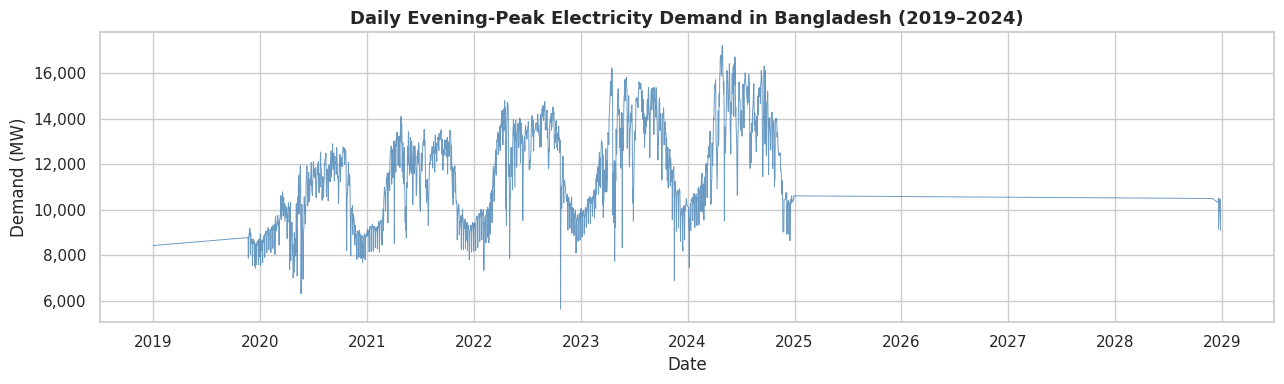

In [19]:
# Demand over time
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(df['Date'], df['Demand'], color='steelblue', lw=0.7, alpha=0.8)
ax.set_title('Daily Evening-Peak Electricity Demand in Bangladesh (2019–2024)')
ax.set_xlabel('Date'); ax.set_ylabel('Demand (MW)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout(); plt.savefig('plot_01_demand_trend.png', dpi=130); plt.show()

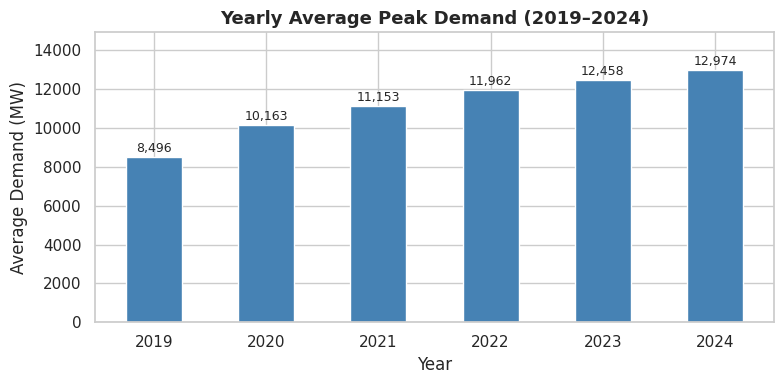

In [20]:
# Yearly average demand (growth trend)
valid_years = [2019, 2020, 2021, 2022, 2023, 2024]
yearly = df[df['Year'].isin(valid_years)].groupby('Year')['Demand'].mean().reset_index()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(yearly['Year'].astype(str), yearly['Demand'], color='steelblue', edgecolor='white', width=0.5)
for bar, val in zip(bars, yearly['Demand']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
            f'{val:,.0f}', ha='center', va='bottom', fontsize=9)
ax.set_title('Yearly Average Peak Demand (2019–2024)')
ax.set_ylabel('Average Demand (MW)'); ax.set_xlabel('Year')
ax.set_ylim(0, yearly['Demand'].max() * 1.15)
plt.tight_layout(); plt.savefig('plot_02_yearly_demand.png', dpi=130); plt.show()

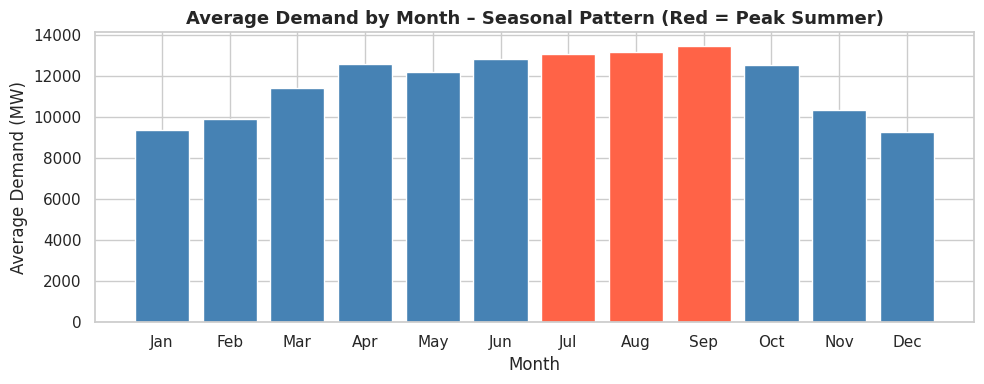

In [21]:
#Monthly seasonality
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
monthly = df.groupby('Month')['Demand'].mean().reset_index()
monthly['MonthName'] = monthly['Month'].apply(lambda x: month_names[x-1])

fig, ax = plt.subplots(figsize=(10, 4))
colors = ['tomato' if m in [7,8,9] else 'steelblue' for m in monthly['Month']]
ax.bar(monthly['MonthName'], monthly['Demand'], color=colors, edgecolor='white')
ax.set_title('Average Demand by Month – Seasonal Pattern (Red = Peak Summer)')
ax.set_ylabel('Average Demand (MW)'); ax.set_xlabel('Month')
plt.tight_layout(); plt.savefig('plot_03_monthly_seasonality.png', dpi=130); plt.show()

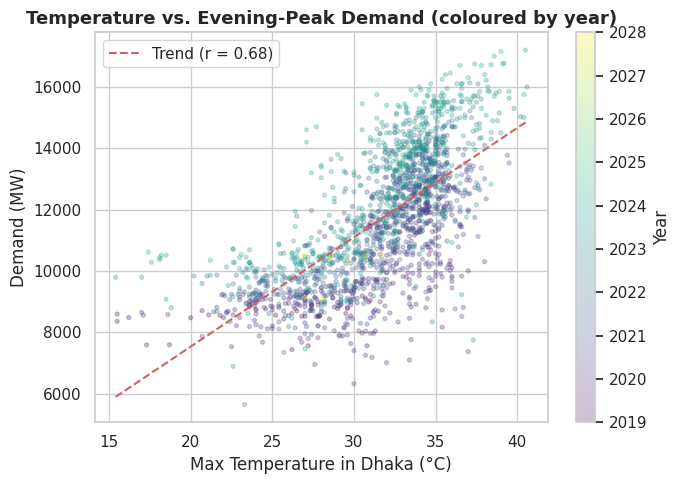

In [22]:
# Temperature vs Demand scatter
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(df['Temperature'], df['Demand'], alpha=0.25, s=8, c=df['Year'], cmap='viridis')
plt.colorbar(sc, ax=ax, label='Year')
# Trend line
m, b = np.polyfit(df['Temperature'].dropna(), df.loc[df['Temperature'].notna(), 'Demand'], 1)
x_range = np.linspace(df['Temperature'].min(), df['Temperature'].max(), 100)
ax.plot(x_range, m*x_range + b, 'r--', lw=1.5, label=f'Trend (r = 0.68)')
ax.set_title('Temperature vs. Evening-Peak Demand (coloured by year)')
ax.set_xlabel('Max Temperature in Dhaka (°C)'); ax.set_ylabel('Demand (MW)')
ax.legend()
plt.tight_layout(); plt.savefig('plot_04_temp_demand.png', dpi=130); plt.show()

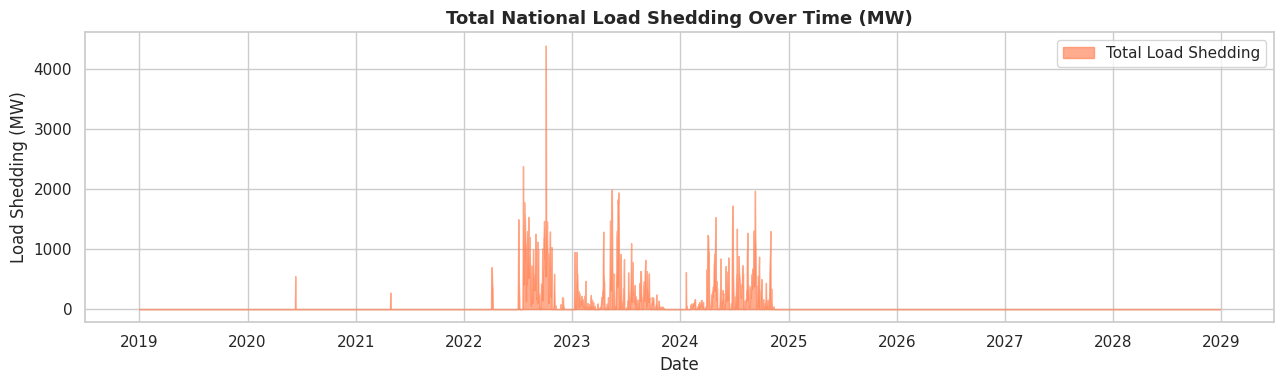

In [23]:
# Load shedding over time
fig, ax = plt.subplots(figsize=(13, 4))
ax.fill_between(df['Date'], df['Total_LoadShed'], alpha=0.65, color='coral', label='Total Load Shedding')
ax.set_title('Total National Load Shedding Over Time (MW)')
ax.set_xlabel('Date'); ax.set_ylabel('Load Shedding (MW)')
ax.legend()
plt.tight_layout(); plt.savefig('plot_05_load_shedding.png', dpi=130); plt.show()

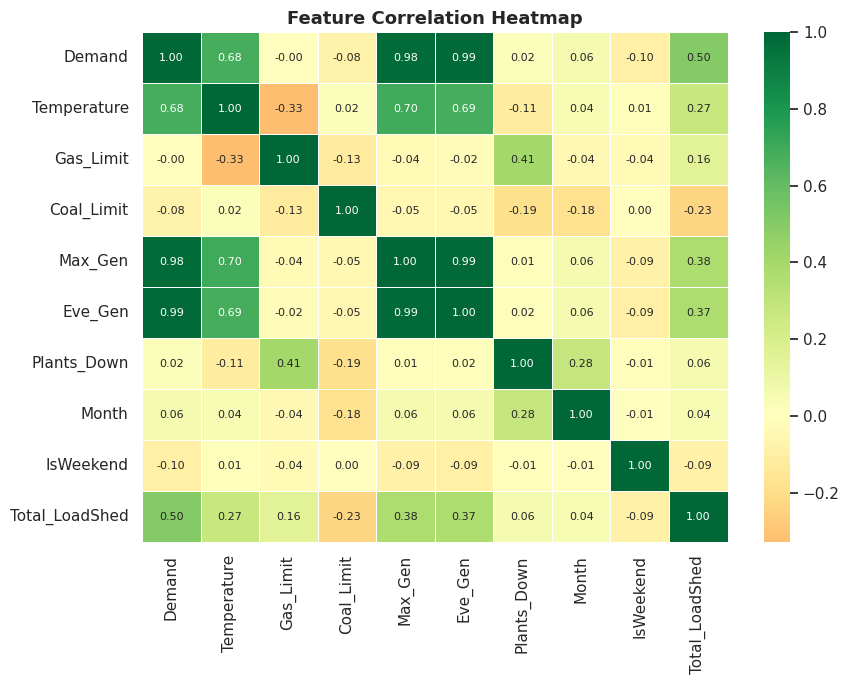

In [24]:
#Correlation heatmap
key_cols = ['Demand', 'Temperature', 'Gas_Limit', 'Coal_Limit',
            'Max_Gen', 'Eve_Gen', 'Plants_Down', 'Month', 'IsWeekend', 'Total_LoadShed']
corr = df[key_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            linewidths=0.4, ax=ax, annot_kws={'size': 8})
ax.set_title('Feature Correlation Heatmap')
plt.tight_layout(); plt.savefig('plot_06_heatmap.png', dpi=130); plt.show()

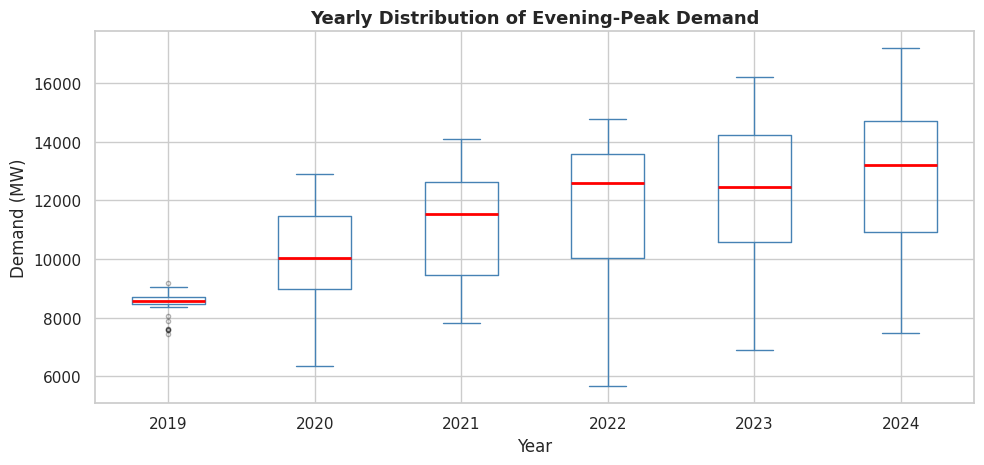

In [25]:
#Yearly demand distribution (box plots)
valid_years = [2019, 2020, 2021, 2022, 2023, 2024]
plot_df = df[df['Year'].isin(valid_years)]

fig, ax = plt.subplots(figsize=(10, 5))
plot_df.boxplot(column='Demand', by='Year', ax=ax,
                boxprops=dict(color='steelblue'),
                medianprops=dict(color='red', lw=2),
                whiskerprops=dict(color='steelblue'),
                capprops=dict(color='steelblue'),
                flierprops=dict(marker='.', alpha=0.3))
ax.set_title('Yearly Distribution of Evening-Peak Demand')
ax.set_xlabel('Year'); ax.set_ylabel('Demand (MW)')
plt.suptitle('')  # remove default suptitle
plt.tight_layout(); plt.savefig('plot_07_boxplot_yearly.png', dpi=130); plt.show()

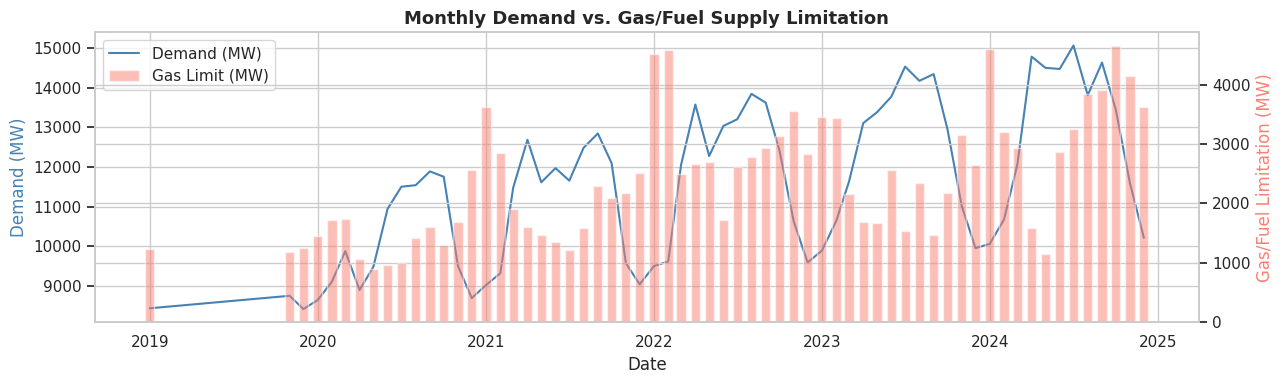

In [26]:
# Gas/Fuel constraint trend vs Demand
monthly_gas = df[df['Year'].isin(valid_years)].groupby(['Year','Month'])[['Demand','Gas_Limit']].mean().reset_index()
monthly_gas['Period'] = pd.to_datetime(monthly_gas[['Year','Month']].assign(day=1))

fig, ax1 = plt.subplots(figsize=(13, 4))
ax2 = ax1.twinx()
ax1.plot(monthly_gas['Period'], monthly_gas['Demand'], color='steelblue', lw=1.5, label='Demand (MW)')
ax2.bar(monthly_gas['Period'], monthly_gas['Gas_Limit'], color='salmon', alpha=0.5, width=20, label='Gas Limit (MW)')
ax1.set_ylabel('Demand (MW)', color='steelblue'); ax2.set_ylabel('Gas/Fuel Limitation (MW)', color='salmon')
ax1.set_xlabel('Date')
ax1.set_title('Monthly Demand vs. Gas/Fuel Supply Limitation')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.tight_layout(); plt.savefig('plot_08_gas_vs_demand.png', dpi=130); plt.show()

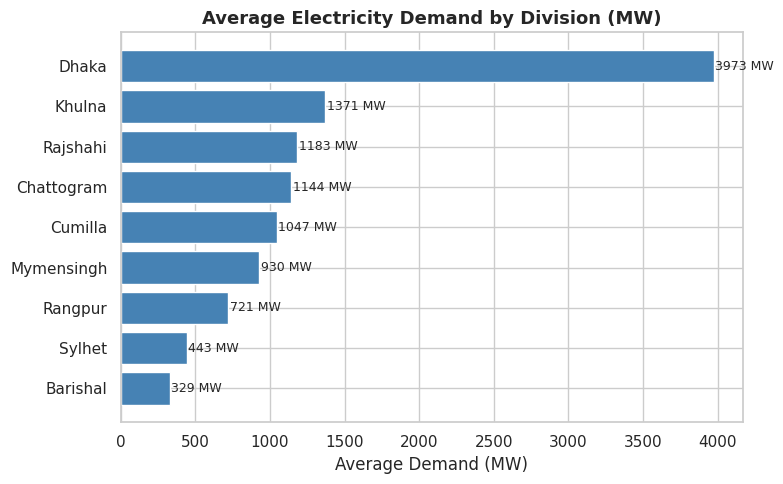

In [27]:
#Regional demand comparison (average MW by division)
regions = ['Dhaka', 'Chattogram', 'Rajshahi', 'Khulna', 'Rangpur', 'Mymensingh', 'Sylhet', 'Barishal', 'Cumilla']
region_demand = {r: df[f'{r}_demand'].mean() for r in regions if f'{r}_demand' in df.columns}
region_df = pd.DataFrame(list(region_demand.items()), columns=['Region','Avg_Demand']).sort_values('Avg_Demand', ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(region_df['Region'], region_df['Avg_Demand'], color='steelblue', edgecolor='white')
for i, (v, r) in enumerate(zip(region_df['Avg_Demand'], region_df['Region'])):
    ax.text(v + 10, i, f'{v:.0f} MW', va='center', fontsize=9)
ax.set_title('Average Electricity Demand by Division (MW)')
ax.set_xlabel('Average Demand (MW)')
plt.tight_layout(); plt.savefig('plot_09_regional_demand.png', dpi=130); plt.show()

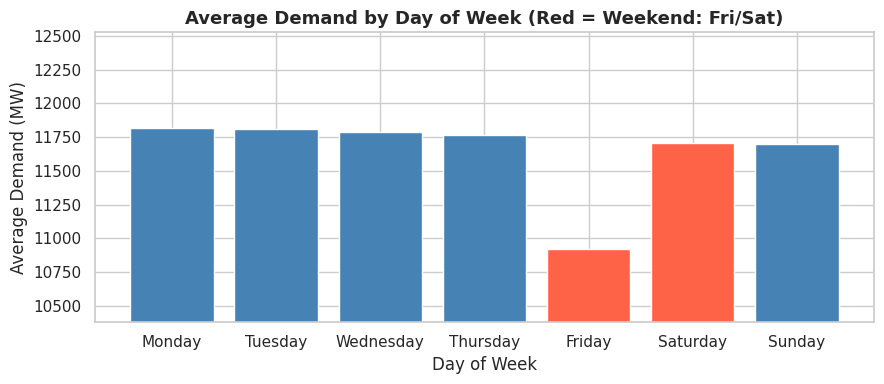

In [28]:
#Demand by day of week
day_names = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dow_demand = df.groupby('DayOfWeek')['Demand'].mean().reset_index()
dow_demand['DayName'] = dow_demand['DayOfWeek'].apply(lambda x: day_names[x])

fig, ax = plt.subplots(figsize=(9, 4))
colors = ['tomato' if d in [4,5] else 'steelblue' for d in dow_demand['DayOfWeek']]
ax.bar(dow_demand['DayName'], dow_demand['Demand'], color=colors, edgecolor='white')
ax.set_title('Average Demand by Day of Week (Red = Weekend: Fri/Sat)')
ax.set_ylabel('Average Demand (MW)'); ax.set_xlabel('Day of Week')
ax.set_ylim(dow_demand['Demand'].min()*0.95, dow_demand['Demand'].max()*1.06)
plt.tight_layout(); plt.savefig('plot_10_weekday_demand.png', dpi=130); plt.show()

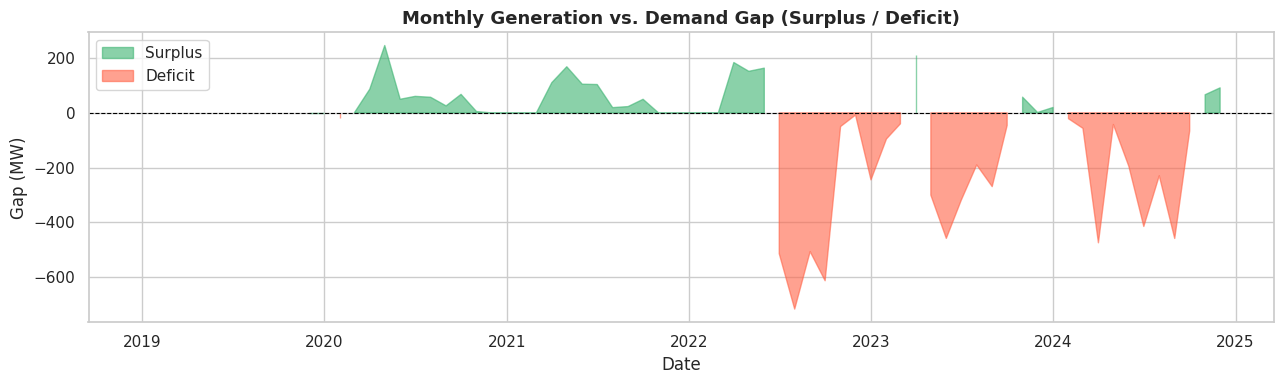

In [29]:
# Generation vs Demand gap (supply shortfall analysis)
df['Gen_Demand_Gap'] = df['Max_Gen'] - df['Demand']

monthly_gap = df[df['Year'].isin(valid_years)].groupby(['Year','Month'])['Gen_Demand_Gap'].mean().reset_index()
monthly_gap['Period'] = pd.to_datetime(monthly_gap[['Year','Month']].assign(day=1))

fig, ax = plt.subplots(figsize=(13, 4))
ax.fill_between(monthly_gap['Period'], monthly_gap['Gen_Demand_Gap'],
                where=monthly_gap['Gen_Demand_Gap'] >= 0, alpha=0.6, color='mediumseagreen', label='Surplus')
ax.fill_between(monthly_gap['Period'], monthly_gap['Gen_Demand_Gap'],
                where=monthly_gap['Gen_Demand_Gap'] < 0, alpha=0.6, color='tomato', label='Deficit')
ax.axhline(0, color='black', lw=0.8, linestyle='--')
ax.set_title('Monthly Generation vs. Demand Gap (Surplus / Deficit)')
ax.set_xlabel('Date'); ax.set_ylabel('Gap (MW)')
ax.legend()
plt.tight_layout(); plt.savefig('plot_11_gen_demand_gap.png', dpi=130); plt.show()

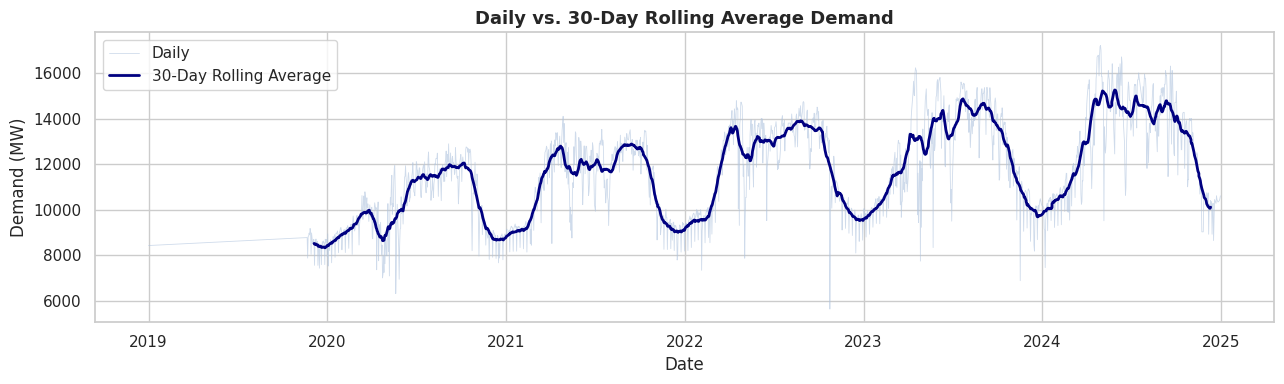

In [30]:
# 30-day rolling average demand (smoothed trend)
df_valid = df[df['Year'].isin(valid_years)].copy()
df_valid['Rolling30'] = df_valid['Demand'].rolling(window=30, center=True).mean()

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(df_valid['Date'], df_valid['Demand'], color='lightsteelblue', lw=0.6, alpha=0.6, label='Daily')
ax.plot(df_valid['Date'], df_valid['Rolling30'], color='navy', lw=2, label='30-Day Rolling Average')
ax.set_title('Daily vs. 30-Day Rolling Average Demand')
ax.set_xlabel('Date'); ax.set_ylabel('Demand (MW)')
ax.legend()
plt.tight_layout(); plt.savefig('plot_12_rolling_avg.png', dpi=130); plt.show()

## Feature Engineering & Model Development

In [31]:
# Feature selection
features = [
    'Temperature', 'Gas_Limit', 'Coal_Limit', 'Water_Limit',
    'Plants_Down', 'Max_Gen', 'Gen_Forecast',
    'Month', 'DayOfWeek', 'IsWeekend'
]
target = 'Demand'

X = df[features]
y = df[target]

# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Feature scaling (for Linear Regression)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print(f'Training samples : {len(X_train)}')
print(f'Test samples     : {len(X_test)}')

Training samples : 1476
Test samples     : 370


In [32]:
# Training all three models
models = {
    'Linear Regression' : (LinearRegression(),                                         True),
    'Random Forest'     : (RandomForestRegressor(n_estimators=100, random_state=42),   False),
    'Gradient Boosting' : (GradientBoostingRegressor(n_estimators=100, random_state=42), False),
}

results = {}
for name, (model, scaled) in models.items():
    Xt = X_train_sc if scaled else X_train
    Xe = X_test_sc  if scaled else X_test
    model.fit(Xt, y_train)
    preds = model.predict(Xe)
    results[name] = {
        'model' : model,
        'preds' : preds,
        'MAE'   : mean_absolute_error(y_test, preds),
        'RMSE'  : np.sqrt(mean_squared_error(y_test, preds)),
        'R2'    : r2_score(y_test, preds)
    }
    print(f'{name:<22}  MAE={results[name]["MAE"]:>7.1f} MW   RMSE={results[name]["RMSE"]:>7.1f} MW   R²={results[name]["R2"]:.4f}')

Linear Regression       MAE=  219.2 MW   RMSE=  455.4 MW   R²=0.9518
Random Forest           MAE=  195.6 MW   RMSE=  455.7 MW   R²=0.9518
Gradient Boosting       MAE=  206.7 MW   RMSE=  430.9 MW   R²=0.9569


##Performance Evaluation

In [33]:
# Summary table
summary = pd.DataFrame({
    name: {'MAE (MW)': round(v['MAE'],1), 'RMSE (MW)': round(v['RMSE'],1), 'R² Score': round(v['R2'],4)}
    for name, v in results.items()
}).T
print('Model Performance Summary')
print(summary.to_string())

Model Performance Summary
                   MAE (MW)  RMSE (MW)  R² Score
Linear Regression     219.2      455.4    0.9518
Random Forest         195.6      455.7    0.9518
Gradient Boosting     206.7      430.9    0.9569


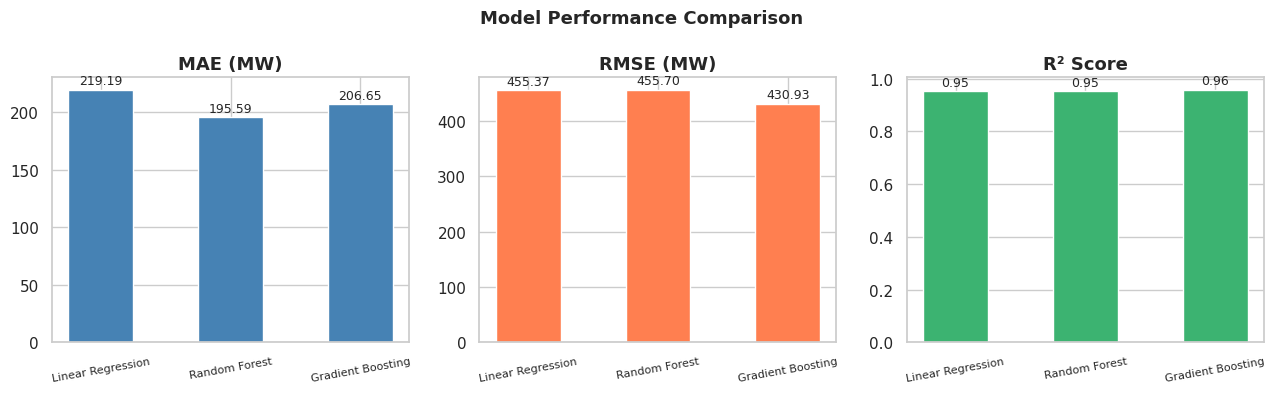

In [34]:
# Model comparison bar chart
model_names = list(results.keys())
maes  = [results[n]['MAE']  for n in model_names]
rmses = [results[n]['RMSE'] for n in model_names]
r2s   = [results[n]['R2']   for n in model_names]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, vals, label, col in zip(axes, [maes, rmses, r2s],
                                 ['MAE (MW)', 'RMSE (MW)', 'R² Score'],
                                 ['steelblue','coral','mediumseagreen']):
    bars = ax.bar(model_names, vals, color=col, edgecolor='white', width=0.5)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+max(vals)*0.01,
                f'{v:.2f}', ha='center', va='bottom', fontsize=9)
    ax.set_title(label); ax.set_xticks(range(len(model_names)))
    ax.set_xticklabels(model_names, rotation=10, fontsize=8)
fig.suptitle('Model Performance Comparison', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig('plot_13_model_comparison.png', dpi=130); plt.show()

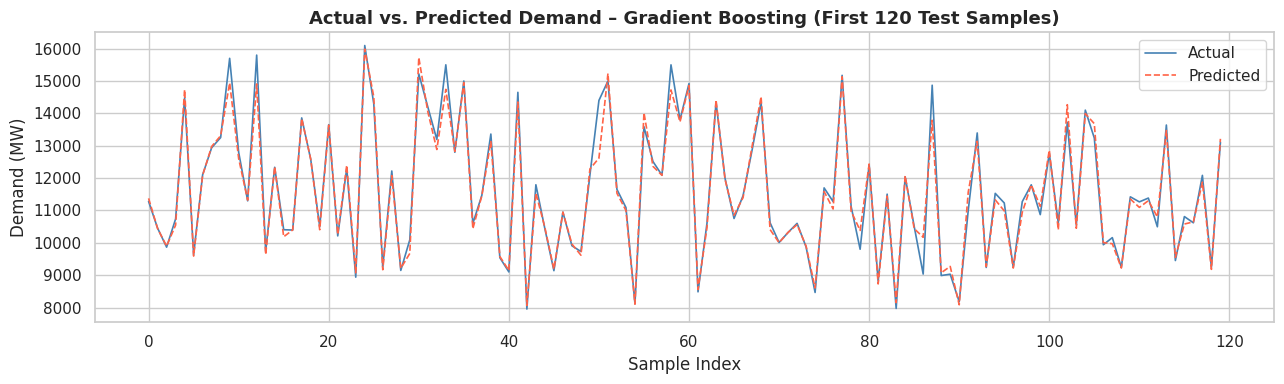

In [35]:
# Actual vs Predicted – best model (Gradient Boosting by RMSE)
best_name = min(results, key=lambda n: results[n]['RMSE'])
best_preds = results[best_name]['preds']
sample = pd.DataFrame({'Actual': y_test.values[:120], 'Predicted': best_preds[:120]})

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(sample['Actual'].values,    label='Actual',    color='steelblue', lw=1.2)
ax.plot(sample['Predicted'].values, label='Predicted', color='tomato', lw=1.2, linestyle='--')
ax.set_title(f'Actual vs. Predicted Demand – {best_name} (First 120 Test Samples)')
ax.set_xlabel('Sample Index'); ax.set_ylabel('Demand (MW)')
ax.legend()
plt.tight_layout(); plt.savefig('plot_14_actual_vs_predicted.png', dpi=130); plt.show()

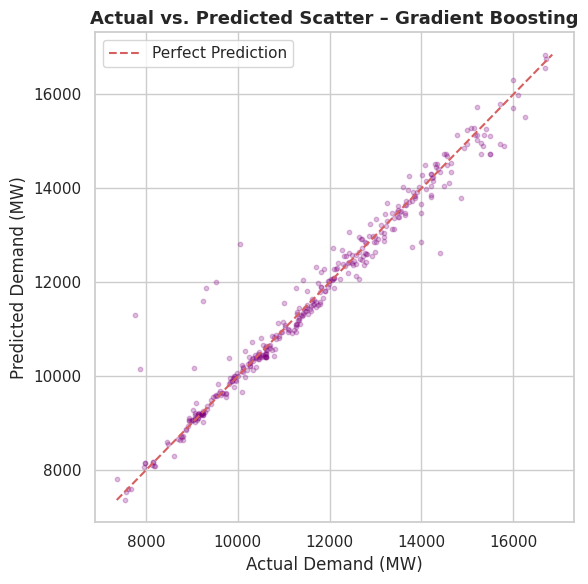

In [36]:
# Scatter: Actual vs Predicted (all test samples)
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, best_preds, alpha=0.25, color='purple', s=10)
lims = [min(y_test.min(), best_preds.min()), max(y_test.max(), best_preds.max())]
ax.plot(lims, lims, 'r--', lw=1.5, label='Perfect Prediction')
ax.set_title(f'Actual vs. Predicted Scatter – {best_name}')
ax.set_xlabel('Actual Demand (MW)'); ax.set_ylabel('Predicted Demand (MW)')
ax.legend()
plt.tight_layout(); plt.savefig('plot_15_scatter.png', dpi=130); plt.show()

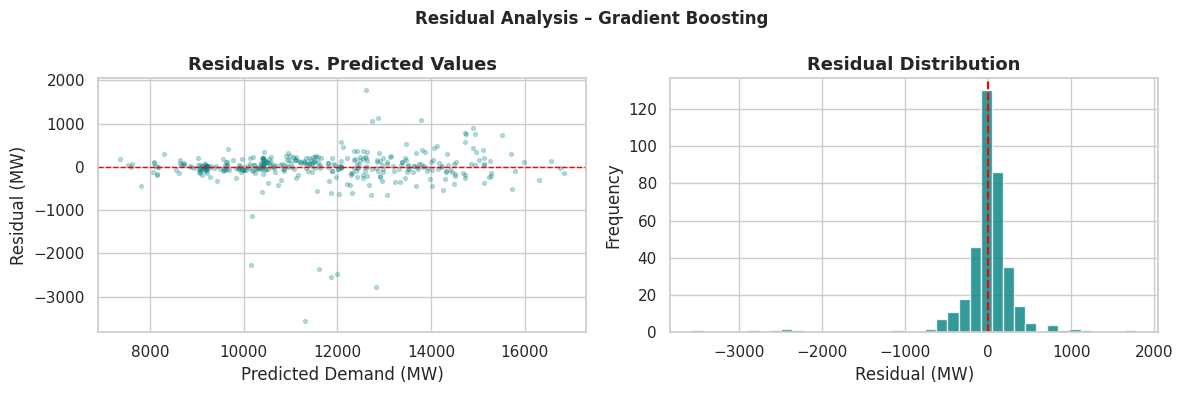

In [37]:
# Residual plot
residuals = y_test.values - best_preds

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(best_preds, residuals, alpha=0.25, color='teal', s=8)
axes[0].axhline(0, color='red', lw=1, linestyle='--')
axes[0].set_title('Residuals vs. Predicted Values')
axes[0].set_xlabel('Predicted Demand (MW)'); axes[0].set_ylabel('Residual (MW)')

axes[1].hist(residuals, bins=40, color='teal', edgecolor='white', alpha=0.8)
axes[1].axvline(0, color='red', lw=1.5, linestyle='--')
axes[1].set_title('Residual Distribution')
axes[1].set_xlabel('Residual (MW)'); axes[1].set_ylabel('Frequency')

plt.suptitle(f'Residual Analysis – {best_name}', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.savefig('plot_16_residuals.png', dpi=130); plt.show()

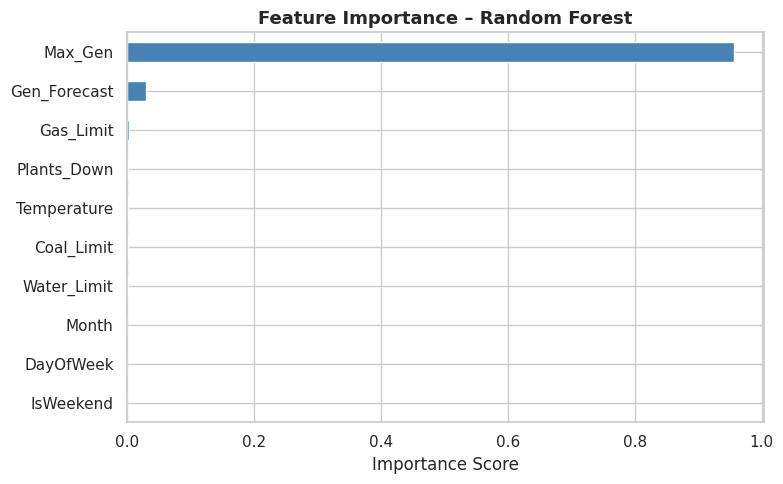

Max_Gen         0.9559
Gen_Forecast    0.0300
Gas_Limit       0.0040
Plants_Down     0.0025
Temperature     0.0022
Coal_Limit      0.0019
Water_Limit     0.0015
Month           0.0008
DayOfWeek       0.0007
IsWeekend       0.0006


In [38]:
# Feature Importance (Random Forest)
rf_model = results['Random Forest']['model']
fi = pd.Series(rf_model.feature_importances_, index=features).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 5))
fi.plot(kind='barh', color='steelblue', edgecolor='white', ax=ax)
ax.set_title('Feature Importance – Random Forest')
ax.set_xlabel('Importance Score')
plt.tight_layout(); plt.savefig('plot_17_feature_importance.png', dpi=130); plt.show()
print(fi.sort_values(ascending=False).round(4).to_string())

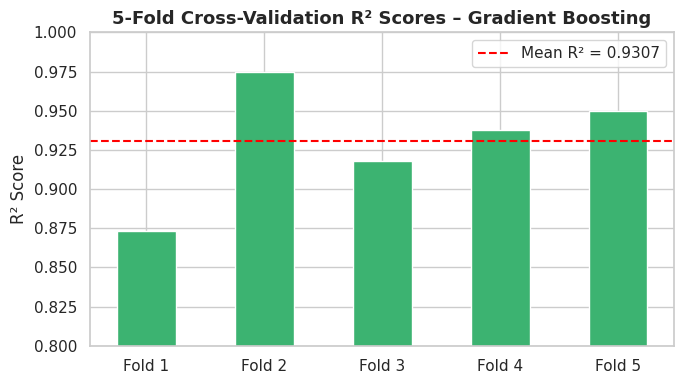

CV R² scores : [0.8733 0.9747 0.9176 0.9378 0.9498]
Mean R²      : 0.9307
Std Dev      : 0.0341


In [39]:
# 5-Fold Cross-Validation
cv_model = GradientBoostingRegressor(n_estimators=100, random_state=42)
cv_scores = cross_val_score(cv_model, X, y, cv=5, scoring='r2')

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar([f'Fold {i+1}' for i in range(5)], cv_scores, color='mediumseagreen', edgecolor='white', width=0.5)
ax.axhline(cv_scores.mean(), color='red', lw=1.5, linestyle='--', label=f'Mean R² = {cv_scores.mean():.4f}')
ax.set_title('5-Fold Cross-Validation R² Scores – Gradient Boosting')
ax.set_ylabel('R² Score'); ax.set_ylim(0.8, 1.0)
ax.legend()
plt.tight_layout(); plt.savefig('plot_18_cross_validation.png', dpi=130); plt.show()

print(f'CV R² scores : {cv_scores.round(4)}')
print(f'Mean R²      : {cv_scores.mean():.4f}')
print(f'Std Dev      : {cv_scores.std():.4f}')